# Signs Extraction

In [7]:
from ultralytics import YOLOE
from PIL import Image

model = YOLOE("task1/yoloe-v8l-seg.pt")
names = [
    "blue rectangle traffic sign",
    "red circular traffic sign",
    "blue circular traffic sign",
    "red triangle traffic sign",
    "green rectangle traffic sign",
    "white rectangle text traffic sign"
]
model.set_classes(names, model.get_text_pe(names))


image 1/1 /Users/mac/Documents/PHUNGPX/vlsp2025-legalqa/data/train_data/train_images/train_2_14.jpg: 448x640 3 blue rectangle traffic signs, 2 red circular traffic signs, 177.1ms
Speed: 0.8ms preprocess, 177.1ms inference, 1.6ms postprocess per image at shape (1, 3, 448, 640)


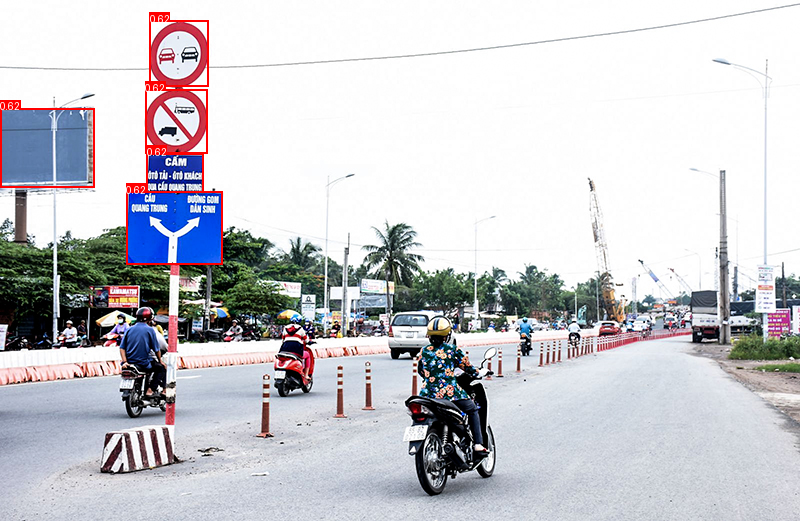

In [ ]:
import supervision as sv
from task1.utils import draw_bboxes, remove_duplicated_boxes, remove_tiny_boxes
from IPython.display import display


image_path = 'data/train_data/train_images/train_2_14.jpg'
image = Image.open(image_path).convert("RGB")
results = model.predict(image_path, conf=0.2)

detections = sv.Detections.from_ultralytics(results[0])

img_with_boxes = draw_bboxes(
    image,
    detections.xyxy,
    detections.confidence,
    detections.data["class_name"],
)
display(img_with_boxes)

In [5]:
!uv pip install supervision

Resolved 22 packages in 1.44s                                        
⠙ Preparing packages... (0/1)                                                   
⠙ Preparing packages... (0/1)--------------     0 B/202.32 KiB          
⠙ Preparing packages... (0/1)-------------- 16.00 KiB/202.32 KiB        
⠙ Preparing packages... (0/1)-------------- 32.00 KiB/202.32 KiB        
⠙ Preparing packages... (0/1)-------------- 38.47 KiB/202.32 KiB        
⠙ Preparing packages... (0/1)-------------- 54.47 KiB/202.32 KiB        
⠙ Preparing packages... (0/1)-------------- 56.58 KiB/202.32 KiB        
⠙ Preparing packages... (0/1)-------------- 72.11 KiB/202.32 KiB        
⠙ Preparing packages... (0/1)-------------- 88.11 KiB/202.32 KiB        
⠹ Preparing packages... (0/1)-------------- 96.00 KiB/202.32 KiB        
⠹ Preparing packages... (0/1)-------------- 96.00 KiB/202.32 KiB        
⠹ Preparing packages... (0/1)m------------- 112.00 KiB/202.32 KiB       
⠹ Preparing packages... (0/1)----------- 128.0


image 1/1 /Users/mac/Documents/PHUNGPX/vlsp2025-legalqa/data/train_data/train_images/train_2_24.jpg: 448x640 2 blue rectangle traffic signs, 3 red circular traffic signs, 1 green rectangle traffic sign, 180.2ms
Speed: 1.4ms preprocess, 180.2ms inference, 1.7ms postprocess per image at shape (1, 3, 448, 640)


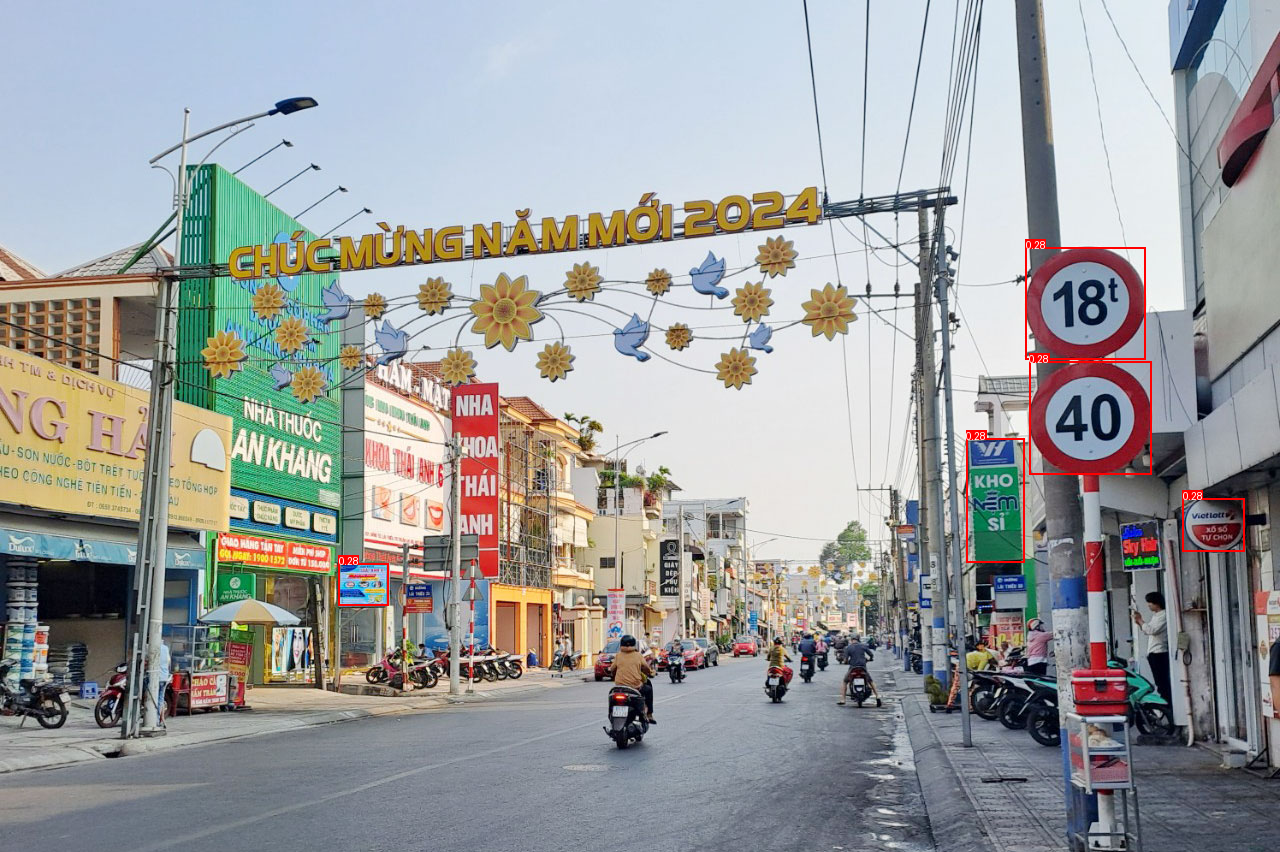

In [12]:
image_path = 'data/train_data/train_images/train_2_24.jpg'
image = Image.open(image_path).convert("RGB")
results = model.predict(image_path, conf=0.2)

detections = sv.Detections.from_ultralytics(results[0])

boxes = detections.xyxy
confidences = detections.confidence
class_names = detections.data["class_name"]

boxes, confidences, class_names = remove_tiny_boxes(boxes, confidences, class_names, image.size, thres=0.05)
boxes, confidences, class_names = remove_duplicated_boxes(boxes, confidences, class_names, iou_thres=0.8)

vis_image = draw_bboxes(image, boxes, confidences, class_names)

display(vis_image)

# Signs Filtering with Gemma3-12B

In [ ]:
import os
import re
import base64
import supervision as sv

from io import BytesIO
from PIL import Image
from pathlib import Path

from task1.utils import LLMClient, remove_duplicated_boxes, remove_tiny_boxes
from dotenv import load_dotenv

load_dotenv()

SIGN_FILTER_PROMPT = """
You are an expert in legal question answering, specializing in traffic and road-related regulations.

You will be provided with:
1. A question related to traffic or road regulations.
2. An original input image.
3. <<NUM_SIGNS>> detected sign(s) from the given image.

Your task:
1. Read the question carefully and determine whether it refers to a sign at a specific position. Explicitly extract the referenced position(s) if present (e.g., left/right/top/bottom/center; near/far; overhead/ahead/behind). If none, state "No explicit position".
2. From the question, identify the expected visual characteristics of the referenced sign, including (if mentioned or implied) its shape, color(s), symbol(s), icon(s), or other notable features. If none, state "No explicit visual features". IMPORTANT: If the question mentions multiple descriptive features (e.g., color AND shape AND icon), then ALL of them must be satisfied simultaneously (logical AND), NOT just one (NOT logical OR).
IMPORTANT COLOR RULE:
In Vietnamese, the phrase "màu xanh" MUST be interpreted as "blue".
Example: If the question says "biển màu xanh", a blue-colored sign will satisfy this condition.
3. Give a concise but complete description of the entire original image, noting road layout, vehicles, pedestrians, environment, and the positions of all detected signs (left/right/top/bottom/center).
4. For EACH detected sign (in the given order), decide whether it is related to the question.
5. When deciding, pay close attention to:
    + The position of the sign in the original image relative to the viewpoint and to any position(s) referenced by the question.
    + Whether the question explicitly or implicitly refers to a specific location or direction (e.g., “sign on the right”, “overhead sign”).
    + The visual appearance and meaning of the sign.
    + If the question is about a prohibitory sign, also consider any supplementary sign(s) immediately below it that is in rectangle shape, contain text or, as they may modify the prohibition’s scope.
6. For EACH sign, explain your reasoning clearly and briefly, including position relevance if applicable.
7. Provide the FINAL decision as a Python-style list of boolean values (True/False), where:
    + EACH ELEMENT MUST CORRESPOND EXACTLY to the matching detected sign in the SAME ORDER they were provided.
    + The length of the list MUST equal <<NUM_SIGNS>>.
8. STRICT REQUIREMENT: The final boolean list MUST contain at least one True value. If no detected sign clearly matches the question, then choose the single most prominent/main sign in the image (e.g., the largest or most central sign) and mark it as True.
9. Enclose ONLY the final boolean list between <<ANSWER>> and <</ANSWER>> tags, with nothing else inside.

Output format:
Question-referenced position(s): ...
Question-referenced visual features: ...
Full image description: ...
Explanation for sign 1: ...
Explanation for sign 2: ...
...
<<ANSWER>>[
    <True/False answer for sign 1>,
    ...
    <True/False answer for sign <<NUM_SIGNS>>>
  ]<</ANSWER>>

IMPORTANT NOTES:
- 4-wheeled vehicles may include car, truck, van, bus, jeep, ...
- 3-wheeled vehicles may include tricycle, auto-rickshaw, cycle rickshaw, ...
- The question may ask about multiple signs, not only one sign.
- "màu xanh" = blue in Vietnamese
- "phương tiện"/"loại xe" = all pedestrians, bicycles, cars, trucks, motorbikes, auto-rickshaws, ...
"""

# In Vietnamese, the phrase "màu xanh" MUST be interpreted as referring to BOTH "green" and "blue".
# Example: If the question says "biển màu xanh", a blue-colored sign AND a green-colored sign BOTH satisfy this condition.

llm_client = LLMClient(base_url=os.getenv("BASE_URL", "https://generativelanguage.googleapis.com/v1beta/openai/"), api_keys=os.getenv("API_KEYS", "").split(","), model_id=os.getenv("MODEL_ID", "gemma-3-12b-it"))

def PILImage_to_base64(image: Image.Image, new_width: int = None) -> str:
    image = image.convert("RGB")
    if new_width is not None:
        new_height = int(image.height / image.width * new_width)
        image = image.resize((new_width, new_height))

    image_bytes = BytesIO()
    mime_type = "image/png"
    image.save(image_bytes, format="PNG")

    image_bytes = image_bytes.getvalue()
    image_base64 = base64.b64encode(image_bytes).decode("utf-8")

    return image_base64, mime_type


def generate_response(
    original_image: Image.Image,
    detected_signs: list[Image.Image],
    question: str,
    model_name: str = "gemma-3-12b-it",
):
    try:
        base64_org_image, org_mime_type = PILImage_to_base64(original_image, None)
        detected_signs_parts = []
        for image in detected_signs:
            base64_image, mime_type = PILImage_to_base64(image, None)
            detected_signs_parts.append(
                {"type": "image_url", "image_url": {"url": f"data:{mime_type};base64,{base64_image}"}}
            )

        parts = [
            {"type": "text", "text": SIGN_FILTER_PROMPT.replace("<<NUM_SIGNS>>", str(len(detected_signs)))
                    + f"\nQuestion: {question}\n"},
            {"type": "text", "text": "Original Image:"},
            {"type": "image_url", "image_url": {"url": f"data:{org_mime_type};base64,{base64_org_image}"}},
            {"type": "text", "text": "Detected Signs (keep this order):"}
        ]

        for i, img in enumerate(detected_signs, 1):
            b64, mt = PILImage_to_base64(img, None)
            parts.extend([
                {"type": "text", "text": f"<<<SIGN {i}>>>"},
                {"type": "image_url", "image_url": {"url": f"data:{mt};base64,{b64}"}},
                {"type": "text", "text": f"<<<END SIGN {i}>>>"}
            ])


        response = llm_client.generate_content(
            contents=[
                {"role": "user", "content": parts},
            ],
            temperature=0.0,
            top_p=1.0,
        )
        return response.text
    except Exception as e:
        raise RuntimeError(f"Error generating response: {str(e)}")


def extract_final_answer(response_text):
    """Extract the final answer from the response text"""
    # Look for <<ANSWER>> ... <</ANSWER>> pattern
    pattern = r"<<ANSWER>>\s*(.*?)\s*<"
    match = re.search(pattern, response_text, re.DOTALL | re.IGNORECASE)

    if match:
        answer_text = match.group(1).strip()
        # Try to parse as a list of boolean values
        try:
            # Handle various formats like [True, False] or [true, false] or True, False
            answer_text = answer_text.replace("true", "True").replace("false", "False")
            if not answer_text.startswith("["):
                answer_text = f"[{answer_text}]"
            answer_list = eval(answer_text)
            return answer_list
        except:
            return answer_text
    return "No answer found"


def batch_list(lst, max_size=5):
    """
    Split list into batches with max size.
    """
    return [lst[i:i + max_size] for i in range(0, len(lst), max_size)]


def detect_and_filter_signs(
    model,
    sample: dict[str, any],
    image_dir,
):
    image_id = sample["image_id"]
    question = sample["question"]

    image_path = image_dir / f"{image_id}.jpg"
    image = Image.open(str(image_path)).convert("RGB")

    results = model(image_path, conf=0.2)
    detections = sv.Detections.from_ultralytics(results[0])

    boxes = detections.xyxy
    confidences = detections.confidence
    class_names = detections.data["class_name"]
    boxes, confidences, class_names = remove_tiny_boxes(boxes, confidences, class_names, image.size, thres=0.05)
    boxes, confidences, class_names = remove_duplicated_boxes(boxes, confidences, class_names, iou_thres=0.8)

    xyxy_boxes = boxes.tolist()

    cropped_signs = []
    for i in range(len(xyxy_boxes)):
        cropped_signs.append(image.crop(xyxy_boxes[i]))

    if len(cropped_signs) == 0:
      return (
        image,
        None,
        [],
        []
    )
    elif len(cropped_signs) == 1:
      return (
        image,
        None,
        cropped_signs,
        [True]
    )

    all_llm_responses = ""
    chosen_signs = []

    print(len(cropped_signs))

    batched_cropped_signs = batch_list(cropped_signs, max_size=5)

    for batch in batched_cropped_signs:
      llm_response = generate_response(image, batch, question)
      chosen_signs.extend(extract_final_answer(llm_response))
      all_llm_responses += llm_response
      all_llm_responses += "\n============\n"

    return (
        image,
        all_llm_responses,
        cropped_signs,
        chosen_signs
    )